In [96]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)

In [97]:

import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [98]:
from functions_generator import *
import time
import heat1D_crank_nicolson_solver as cns

In [99]:
# Parametri simulazione
L = 1
Tf = 10
nt = 250
D = 1
wanted_r = 0.8
h = 1

# Inizializza solver
solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

---------- Solver info
Time scale coeff:       1.00e+00
dx:                     2.50e-01
dt:                     4.00e-02
nt:                     250
nx:                     5
r:                      6.40e-01


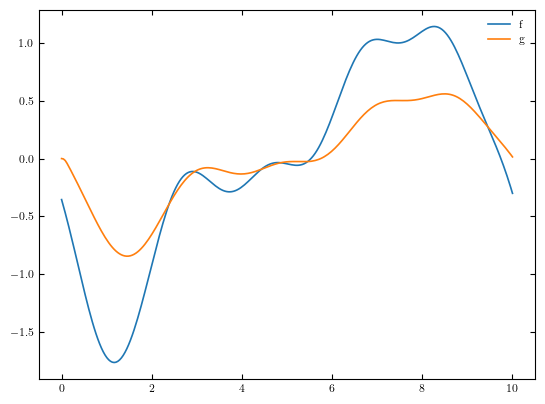

In [100]:
l = 1
f = generate_random_f_from_white_noise(solver.t_array,l=1)
theta = solver.solve(f)
g = theta[solver.nx-1,:]

plt.plot(solver.t_array, f, label="f")
plt.plot(solver.t_array, g, label="g")
plt.legend()
plt.show()

In [ ]:
def loss(f, g_target, lambda_reg : float, cut_index : int = 1):
    
    T = solver.solve(f)
    g_sim = T[-1, :]
    
    # Termine energetico differenza soluzione trovata e soluzione nota
    misfit = np.linalg.norm(g_sim[:-cut_index] - g_target[:-cut_index])**2

    # Termine fisico per limitare le ampiezze
    #reg = lambda_reg * np.linalg.norm(f[:])**2

    # Termine energetico sulla derivata
    reg = lambda_reg * np.linalg.norm(np.diff(f))**2

    return misfit + reg

In [ ]:
from scipy.optimize import minimize

lambda_reg = 1e-5

# Aggiungo noise gaussiano
noise_level = 0 

T_target = g
f_guess = np.zeros(nt)
result = minimize(
    loss,
    f_guess,
    args=(T_target, lambda_reg),
    method='L-BFGS-B',
    options={'maxiter': 50}
)

f_reconstructed = result.x

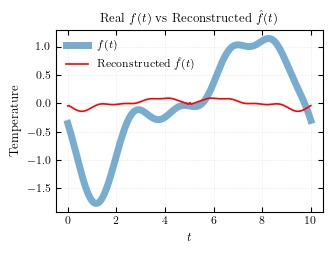

In [104]:
plt.figure(figsize=(3.4, 2.6))
plt.plot(solver.t_array, f, label=r"$f(t)$", lw=5, alpha=0.6)
plt.plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
plt.xlabel(r"$t$")
plt.ylabel("Temperature")
plt.title(r"Real $f(t)$ vs Reconstructed $\hat{f}(t)$")
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig("assets/tikonov_reconstructed_function.pdf")
plt.show()

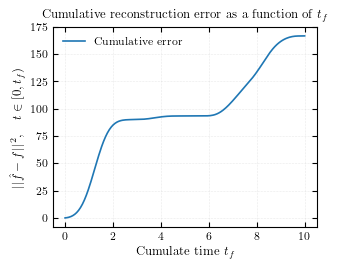

In [105]:
loss_array = np.zeros(nt)

for n in range(nt):
    loss_array[n] = np.linalg.norm(f[0:n] - f_reconstructed[0:n])**2

plt.figure(figsize=(3.4, 2.6))
plt.plot(solver.t_array, loss_array, label="Cumulative error")
plt.ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
plt.xlabel(r"Cumulate time $t_f$")
plt.title(r"Cumulative reconstruction error as a function of $t_f$")
plt.legend()
plt.grid()
plt.show()